# FPL Points Prediction - Model Evaluation

#### Team
- Andy Pike
- Mubeen Yaqub
- Sarjit Kaswala
- Sumedha Na

## 1. Background

### Preparing Our Data

FPL data is a time series so a temporal split is neceesary to avoid data leakage.
- **Train**: All historical seasons (2020–25) + Gameweeks 1–5 of 2025-26
- **Test**: Gameweeks 6–25 of 2025-26 (the season in progress)

We chose GW5 as the training cutoff for two reasons so new players joining mid-season need at least 5 games of history before the 5-game moving average features  become meaningful. Cutting earlier means most new players would have NaN features. Also a larger test set (GW6–25 = 20 gameweeks) gives more robust evaluation than just a handful of gameweeks. In production, this system would download the latest gameweek data and only predict the next game. However, for the purposes of testing out our models we predict multiple games at a time.

##### Interesting Parts of the Code

We decided engineer lag and moving average features on a per player basis to help the model learn the patterns in our time series. Lag 1 features react quickly to form changes but are noisy. MA5 features are more stable but lag behind sudden improvements or injuries. Using both gives the model short-term and medium-term signals simultaneously. 

```python
df = df.sort_values(['element', 'season', 'round']
df[f'{col}_lag1'] = df.groupby('element')[col].shift(1)
```

This ensures that for any row at Gameweek N, the features only contain information from GW N-1 and earlier. Without shift(1), the rolling average for GW N would include GW N's own score, which would be data leakage. To do this accurately we had to sort the gameweek data chronolgically and group by player (the FPL player identifier is 'element').F ull code for lag and moving average can be found in src/feature_engineering.py.  


We also applied an exponential decay to weight recent player performance more heavily. To do this we had to convert seasons and gameweeks (38 per season) into a tieline.

```
timeline = season_index × 38 + gameweek
```

Here's how that looks in practice:
- GW5 of 2025-26 → 5 × 38 + 5 = 195
- GW38 of 2024-25 → 4 × 38 + 38 = 190
- GW1 of 2020-21 → 0 × 38 + 1 = 1

We then calculated gameweeks ago (195 is gameweek 5 of the current season, which is our cutoff point.)

```
gameweeks_ago = 195 − timeline
```

So GW38 of 2024-25 is 195 − 190 = 5 gameweeks ago, and GW1 of 2020-21 is 195 − 1 = 194 gameweeks ago. This is then used to calculate the weight accordin to the formula below. -0.15 was chosen arbirtarily. We will experiment with tuning this parameter. These weights are stored in the sample_weight column of data/train.csv and passed to each model at fit time.

```
weight = exp(-0.15 × gameweeks_ago)
```

Weights are always between 0 and 1:
- gameweeks_ago = 0 -> exp(0) = 1.0` (maximum weight — the most recent training data)
- gameweeks_ago = 5 -> exp(-0.75) ≈ 0.47` (roughly half weight)
- gameweeks_ago = 38 -> exp(-5.7) ≈ 0.003 (near zero - effectively ignord)

### Features Selected

**Target variable:** `total_points` — the FPL points a player scores in a given gameweek. This is the raw points total including goals, assists, clean sheets, bonus points, and deductions.

We chose the following features based on the correlation analysis in our EDA:

| Feature | Type | Why it was chosen |
|---|---|---|
| `total_points_lag1` | lag1 | Direct signal of recent output; captures the immediate momentum of a player's last performance |
| `total_points_ma5` | ma5 | Smoothed points trend; reduces noise from one-off hauls or blanks |
| `expected_goal_involvements_lag1` | lag1 | xGI (xG + xA) reflects underlying attacking threat more reliably than actual goals/assists, which are noisier |
| `expected_goal_involvements_ma5` | ma5 | Sustained attacking involvement over 5 weeks — a better signal of consistent returns than a single week |
| `minutes_lag1` | lag1 | Availability proxy; a player who played 90 minutes last week is more likely to start this week |
| `ict_index_ma5` | ma5 | FPL's composite influence/creativity/threat score; captures attacking involvement beyond xGI alone |
| `bps_ma5` | ma5 | Bonus point system score; reflects consistently high-quality performances that earn bonus points |

### Models Selected

We wanted to use Random Forest and Gradient Boosting because they are highly accurate at modeling complex non-linear relationships in tabular data with minimal preprocessing or hyperparameter tuning. We want to compliment these models with a linear model as a baseline. We just Ridge for this purpose. Additionally we used two naive models as additional baselines: lag1 (ie this week's points will be the same as last week) and MA5 (this week's points will be the average points from the last 5 weeks)

### Evaluation metrics

Our primary evaluation metric is Mean Absolute Error. This measures the average of |actual − predicted| across all player-gameweeks. Our goal is to predict the number of points each player will score. Ths metric is highly interpretable. An MAE of 1.03 means the model is off by about 1 point per player per gameweek on average. We also use RMSE which is the square root of the average of (actual − predicted)². This metric heavily penalizes large errors. This is important because in FPL we can only choose 11 players and we are trying to identify who will score the most points each weeks. We also use R², which measures how much of the variation in player scores the model explains. 

## 2.Results

In [55]:
import pandas as pd
import numpy as np
import json
import math
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')

test_df = pd.read_csv('../data/test.csv')
predictions_df = pd.read_csv('../data/predictions_tuned.csv')

with open('../metrics/results.json', 'r') as f:
    metrics = json.load(f)


# Inspect test set
print(f"Test set: {len(test_df)} rows")
print(f"Gameweeks: {test_df['round'].min()} to {test_df['round'].max()}")

Test set: 16187 rows
Gameweeks: 6 to 26


In [56]:
# Display metrics from JSON
metrics_df = pd.DataFrame(metrics).T
metrics_df = metrics_df.sort_values('mae')
print("Model Performance (sorted by MAE):")
print(metrics_df.to_string())

Model Performance (sorted by MAE):
                      mae    rmse      r2
random_forest      1.0306  1.9777  0.3077
gradient_boosting  1.0566  2.0037  0.2894
naive_ma5          1.0573  2.1159  0.2076
ridge_regression   1.0772  1.9733  0.3108
naive_lag1         1.1494  2.5968 -0.1935


**Reading the results:** The test set spans 20 gameweeks (GW6–26) of the 2025-26 season and covers **16,187 player-gameweek rows**. Following best practices for model evaluation, all five models are evaluated on a *held-out test set* — data the models never saw during training — to give an unbiased estimate of generalisation performance. Three complementary metrics are reported:

- **MAE** (Mean Absolute Error): the average absolute difference between predicted and actual FPL points. This is our **primary metric**. An MAE of ~1.03 means predictions are off by roughly **1 point per player per gameweek** on average — an intuitive, directly interpretable number.
- **RMSE** (Root Mean Squared Error): the square root of the average *squared* error. Because it squares errors before averaging, it penalises large mis-predictions more heavily than MAE. Lower is better. RMSE is always ≥ MAE; a large gap between the two signals that a model is occasionally making very large errors.
- **R²** (coefficient of determination): the proportion of *variance* in player scores explained by the model. A value of 0.31 means the model explains about **31% of the variation** in points; the remaining 69% is attributable to noise (injuries, rotation, luck). An R² of 0 means the model is no better than always predicting the mean; negative R² means it is *worse* than that baseline.

Multiple metrics are reported deliberately — as covered in the course, no single metric tells the whole story, and different use cases may weight them differently (e.g. minimising worst-case errors vs. average error).


## 3. Observations and Conclusions



The table above summarises model performance. We include two **naive baselines** (Lag1 and MA5) alongside the trained models — a recommended practice, since a sophisticated model that cannot beat a simple baseline provides little value. The following observations explore what the numbers reveal about model behaviour and the inherent difficulty of predicting FPL points.


## Model Performance Overview

Five models were evaluated on Gameweeks 6–26 of the 2025-26 FPL season (16,187 test rows). The metrics used were MAE (Mean Absolute Error), RMSE (Root Mean Squared Error), and R² (coefficient of determination).

| Model             | MAE   | RMSE  | R²     |
| ----------------- | ----- | ----- | ------ |
| Random Forest     | 1.031 | 1.978 | 0.308  |
| Gradient Boosting | 1.057 | 2.004 | 0.289  |
| Naive MA5         | 1.057 | 2.116 | 0.208  |
| Ridge Regression  | 1.077 | 1.973 | 0.311  |
| Naive Lag1        | 1.149 | 2.597 | -0.194 |

## Observations

**Random Forest achieved the lowest MAE (1.031)**, edging out Gradient Boosting and the Naive MA5 baseline. This confirms that ensemble tree methods, which combine many weak learners to reduce variance, effectively capture the non-linear patterns in FPL points without overfitting to the training data.

**Ridge Regression achieved the highest R² (0.311) and lowest RMSE (1.973)** despite its higher MAE. The linear model with L2 regularisation appears to constrain extreme predictions, resulting in fewer large errors — which is why RMSE (which penalises large errors more heavily) favours it over Random Forest. This trade-off between average error (MAE) and worst-case error (RMSE) is worth considering based on the intended use case.

**Naive MA5 (MAE = 1.057) is surprisingly competitive** with the trained ML models, indicating that a player's 5-game moving average is already a very strong signal. The marginal improvement from ML suggests diminishing returns from model complexity alone — and points toward the need for richer *features* (e.g. fixture difficulty, opponent strength) rather than more complex model architectures.

**Naive Lag1 is the weakest model (R² = −0.194)**, performing worse than simply predicting the mean. The negative R² confirms this — it fails to beat the trivial "always predict the mean" baseline. A single prior gameweek score is too noisy and volatile; this demonstrates why the MA5 smoothing was an important feature engineering decision.

**All R² values are low (0.2–0.31)**, which is expected in FPL prediction. Player points are highly stochastic due to injuries, rotation, and fixture difficulty. This reflects an inherent **irreducible error** floor: no model can predict genuinely random events. The relatively narrow MAE spread (1.03–1.15) across all five models also suggests the problem is feature-limited, not model-limited — a direction addressed in the Conclusion.


## Conclusion

The **temporal train/test split** (train on GW1–5, test on GW6–26) and **exponential decay weighting** were sound design choices that prevent data leakage and prioritise recent form. A time-based split is essential for time-series data — randomly splitting rows would allow the model to "see the future" during training, giving deceptively optimistic metrics on the test set.

The lag and moving average features add meaningful value over Lag1 alone, but future work should focus on **feature engineering** rather than model complexity: adding opponent strength, fixture difficulty ratings (FDR), or team form could push R² meaningfully higher. As covered in the course, improvements in the *data and features* tend to outperform improvements to model architecture when the current feature set is the bottleneck.

The **decay parameter (−0.15)** was chosen arbitrarily and should be treated as a **hyperparameter** — tuned via cross-validation (e.g. grid search or random search over a log-scale range) rather than set manually. Using a validation split separate from the test set is important here: tuning against the test set would inflate reported performance and undermine the integrity of the evaluation.

For production deployment, **Random Forest** is recommended if minimising average prediction error (MAE) is the priority, while **Ridge Regression** is the better choice if minimising large prediction errors (RMSE) matters most — for example, when avoiding badly mispredicting high-ceiling players (strikers in good form, penalty takers) is critical to FPL squad selection.


# 5. Prediction EDA — Where Models Performed Well and Failed

Beyond the headline metrics, we dig deeper into *where* the models succeed and where they struggle — by player position, gameweek, haul-detection ability, and team. This helps identify systematic weaknesses and guide future feature engineering.


## Correlation Analysis

The heatmap below shows pairwise correlations between the engineered features and the target (`total_points`). Features with a strong positive correlation to `total_points` are the most informative for prediction. Notice that `total_points_lag1`, `total_points_ma5`, and `bps_ma5` tend to correlate most strongly with the target, validating our feature selection choices.


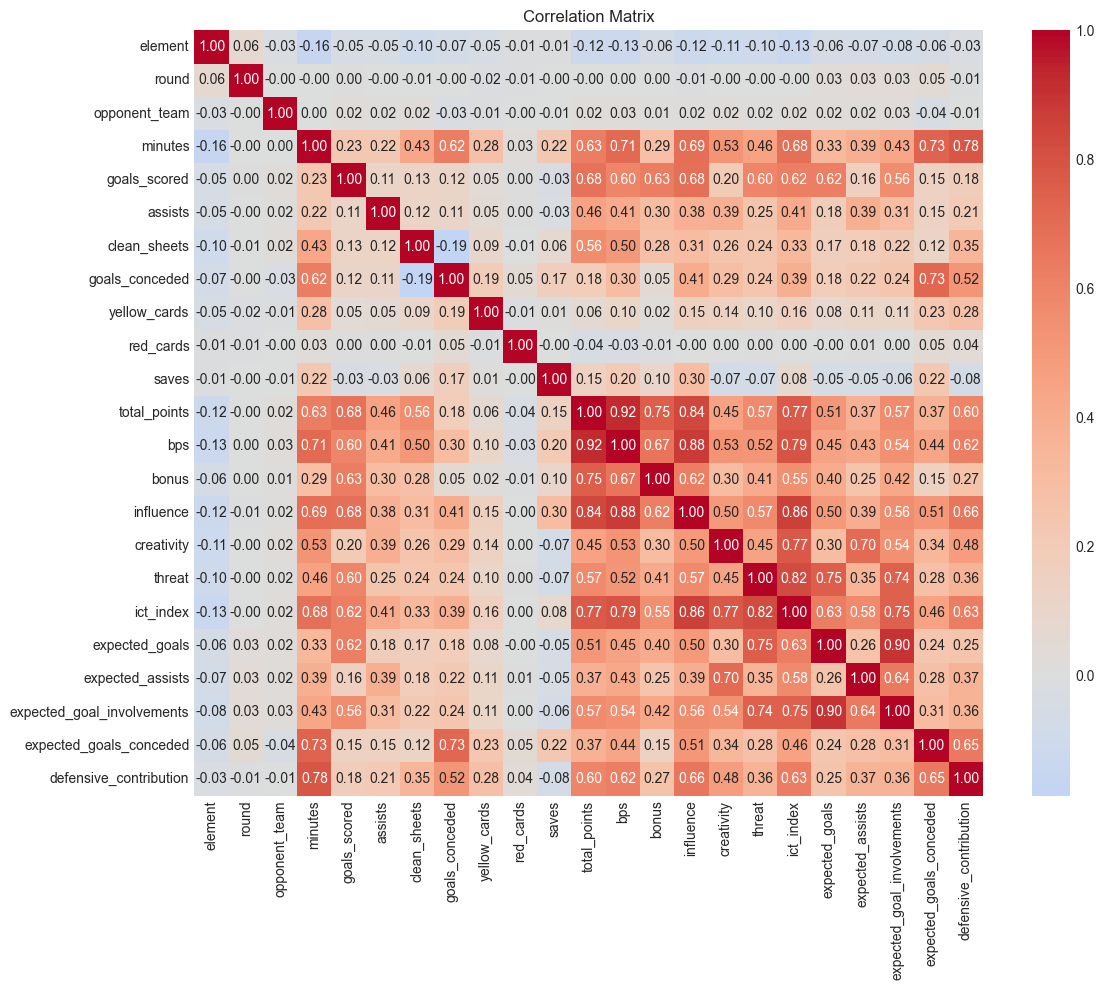

In [57]:
df = pd.read_csv('../data/raw/combined_all_seasons.csv')
numeric_cols = df.select_dtypes(include=[np.number]).columns
plt.figure(figsize=(12, 10))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [58]:
import joblib

# Compute residuals for each model
pred_df = predictions_df.copy()
pred_df['residual_ridge'] = pred_df['total_points'] - pred_df['pred_ridge']
pred_df['residual_rf']    = pred_df['total_points'] - pred_df['pred_rf']
pred_df['residual_gb']    = pred_df['total_points'] - pred_df['pred_gb']
pred_df['abs_error_ridge'] = pred_df['residual_ridge'].abs()
pred_df['abs_error_rf']    = pred_df['residual_rf'].abs()
pred_df['abs_error_gb']    = pred_df['residual_gb'].abs()

print(f"Predictions: {len(pred_df)} rows")
print(pred_df[['total_points','pred_ridge','pred_rf','pred_gb']].describe().round(2))

Predictions: 16187 rows
       total_points  pred_ridge   pred_rf   pred_gb
count      16187.00    16187.00  16187.00  16187.00
mean           1.17        0.78      0.76      0.76
std            2.38        0.91      0.88      0.91
min           -3.00        0.13      0.08      0.02
25%            0.00        0.17      0.09      0.09
50%            0.00        0.19      0.17      0.16
75%            1.00        1.52      1.51      1.48
max           23.00        5.36      3.87      4.96


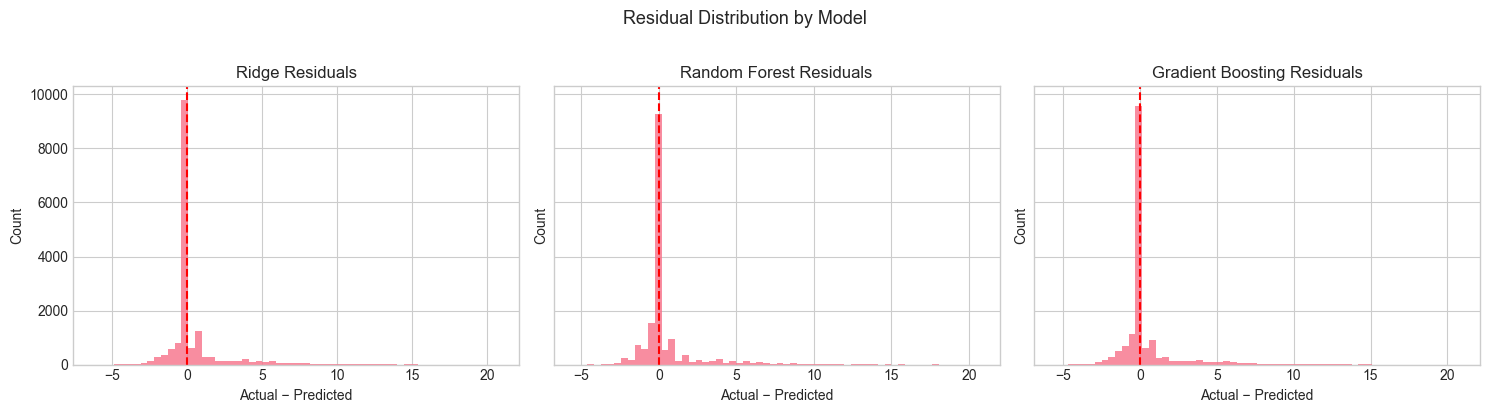

In [59]:
## Error distribution by model
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col, label in zip(axes,
                           ['residual_ridge', 'residual_rf', 'residual_gb'],
                           ['Ridge', 'Random Forest', 'Gradient Boosting']):
    ax.hist(pred_df[col], bins=60, edgecolor='none', alpha=0.8)
    ax.axvline(0, color='red', linewidth=1.5, linestyle='--')
    ax.set_title(f'{label} Residuals')
    ax.set_xlabel('Actual − Predicted')
    ax.set_ylabel('Count')
plt.suptitle('Residual Distribution by Model', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Error Distribution Interpretation

The histograms above show the distribution of residuals (predicted − actual) for Ridge Regression, Random Forest, and Gradient Boosting. Well-calibrated models should show residuals **centred near zero** with a roughly symmetric, bell-shaped distribution.

- A distribution skewed **right (positive)** means the model tends to *under-predict* — it misses players who score big hauls (goals, clean sheets, bonuses stacking together).
- A distribution skewed **left (negative)** means the model tends to *over-predict* — common for rotation-risk players who were expected to play but didn't.
- **Heavy tails** indicate the model struggles with extreme outcomes (very high or very low scoring gameweeks), which is expected given the stochastic nature of FPL points. This is reflected in the RMSE being substantially higher than MAE for all models.


MAE by Position:
          Ridge  Random Forest  Gradient Boosting
position                                         
DEF       1.107          1.068              1.074
FWD       0.986          0.917              0.933
GK        0.589          0.529              0.540
MID       0.947          0.897              0.904


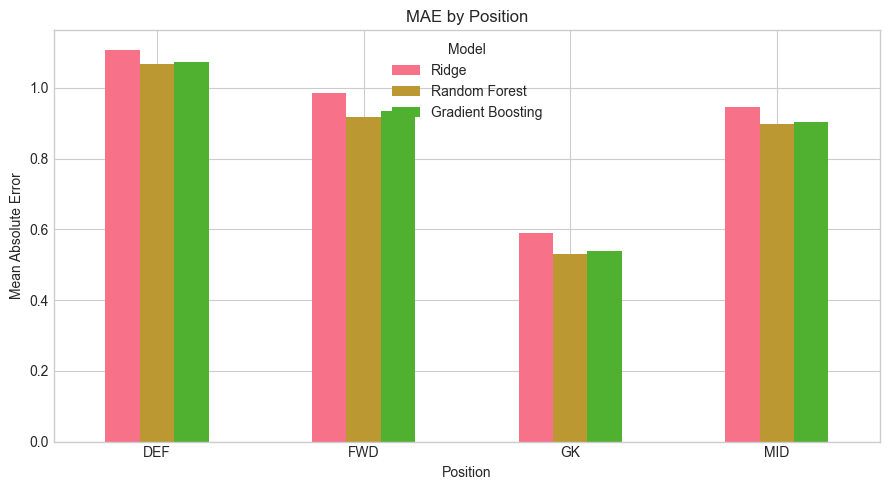

In [60]:
## MAE by position
position_mae = pred_df.groupby('position')[['abs_error_ridge','abs_error_rf','abs_error_gb']].mean()
position_mae.columns = ['Ridge', 'Random Forest', 'Gradient Boosting']
print("MAE by Position:")
print(position_mae.round(3))

position_mae.plot(kind='bar', figsize=(9, 5))
plt.title('MAE by Position')
plt.xlabel('Position')
plt.ylabel('Mean Absolute Error')
plt.xticks(rotation=0)
plt.legend(title='Model')
plt.tight_layout()
plt.show()

### MAE by Position Interpretation

FPL positions have very different scoring profiles, so we expect MAE to vary significantly:

- **Forwards (FWD)** and **Midfielders (MID)** tend to have higher MAE because their scores are more volatile — a single goal or assist (2–5 pts) or a blank is highly unpredictable game-to-game.
- **Defenders (DEF)** and **Goalkeepers (GK)** scores are more binary (clean sheet bonus is the main driver), which can make them easier or harder to predict depending on fixture difficulty.

Positions with consistently higher MAE are candidates for targeted feature engineering — for example, adding a "clean sheet probability" feature for defenders, or an "expected goals" (xG) feature tuned to attackers' shooting positions.


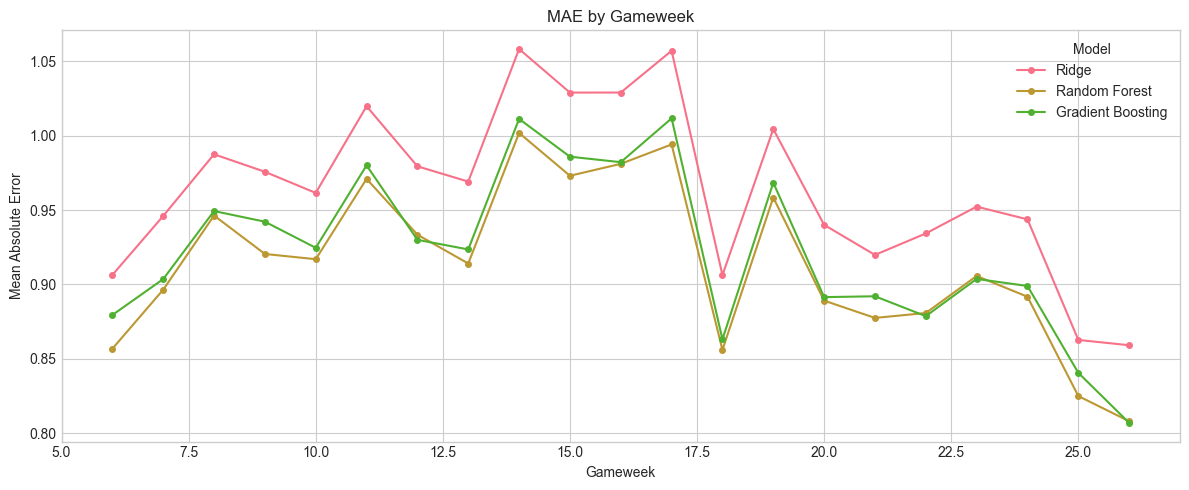

In [61]:
## MAE by gameweek (round)
gw_mae = pred_df.groupby('round')[['abs_error_ridge','abs_error_rf','abs_error_gb']].mean()
gw_mae.columns = ['Ridge', 'Random Forest', 'Gradient Boosting']

gw_mae.plot(figsize=(12, 5), marker='o', markersize=4)
plt.title('MAE by Gameweek')
plt.xlabel('Gameweek')
plt.ylabel('Mean Absolute Error')
plt.legend(title='Model')
plt.tight_layout()
plt.show()

### MAE by Gameweek Interpretation

Tracking MAE across gameweeks reveals whether model performance is **stable over time** or drifts as the season progresses.

- **Spikes in MAE** on certain gameweeks typically correspond to unpredictable events: double gameweeks (players play twice), fixture congestion, or major injury/suspension waves. These are structurally hard to predict.
- A **gradual upward trend** in MAE over gameweeks could indicate *model staleness* — the training data from GW1–5 becomes less representative as the season evolves, player form changes, and new players emerge. This supports the case for **rolling retraining** in a production system, where the model is updated each week with the latest data.
- Relatively **flat MAE** across gameweeks would validate the exponential decay weighting strategy, confirming that prioritising recent training data keeps the model relevant.


High-scoring events (>=12 pts): 145 rows
Avg RF prediction for these: 1.98 pts
Avg actual for these:        14.02 pts



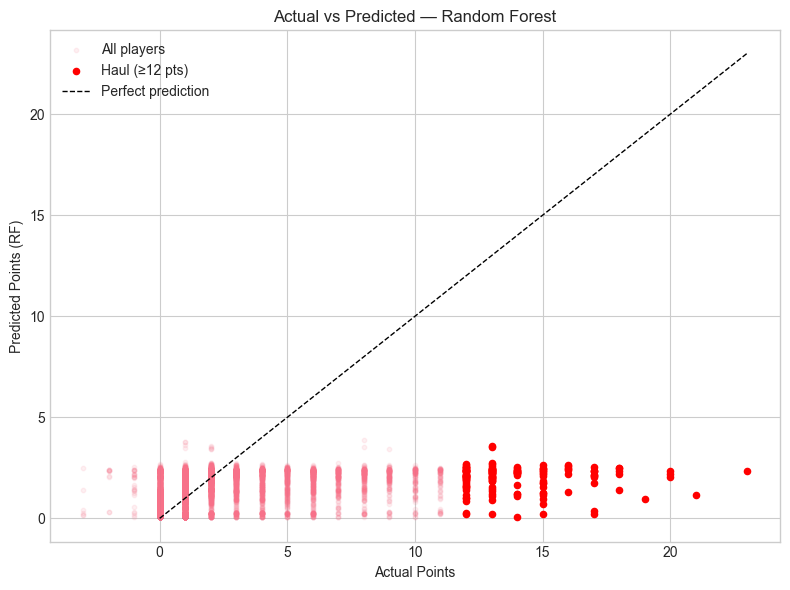

In [62]:
## High-scoring gameweeks — did models catch the big hauls?
# Flag rows where actual points >= 12 (hat tricks, big clean sheets, etc.)
hauls = pred_df[pred_df['total_points'] >= 12].copy()
print(f"High-scoring events (>=12 pts): {len(hauls)} rows")
print(f"Avg RF prediction for these: {hauls['pred_rf'].mean():.2f} pts")
print(f"Avg actual for these:        {hauls['total_points'].mean():.2f} pts\n")

# Scatter: actual vs predicted for RF, highlighting hauls
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(pred_df['total_points'], pred_df['pred_rf'], alpha=0.1, s=10, label='All players')
ax.scatter(hauls['total_points'], hauls['pred_rf'], color='red', s=20, label='Haul (≥12 pts)')
ax.plot([0, pred_df['total_points'].max()], [0, pred_df['total_points'].max()],
        'k--', linewidth=1, label='Perfect prediction')
ax.set_xlabel('Actual Points')
ax.set_ylabel('Predicted Points (RF)')
ax.set_title('Actual vs Predicted — Random Forest')
ax.legend()
plt.tight_layout()
plt.show()

### Haul Detection Interpretation

In FPL, correctly identifying **high-scoring gameweeks** (≥ 12 points — typically involving a goal + assist + clean sheet or a hat-trick) is disproportionately valuable. Selecting a player who scores 15 points is far more impactful than correctly predicting ten 3-point performances.

- If models **under-detect hauls** (low recall on high-scoring rows), this reflects a systematic bias toward "average" predictions — a common consequence of MAE optimisation, which discourages extreme predictions.
- The MA5 feature, by design, smooths out spikes, meaning it may suppress haul predictions. Including a **variance** or **maximum recent score** feature could help capture players with upside potential.
- This is a known limitation of regression-based FPL models: they optimise for average accuracy, not for identifying outlier performances. A complementary classification model (e.g. "will this player score ≥ 12 points?") could be explored in future work.


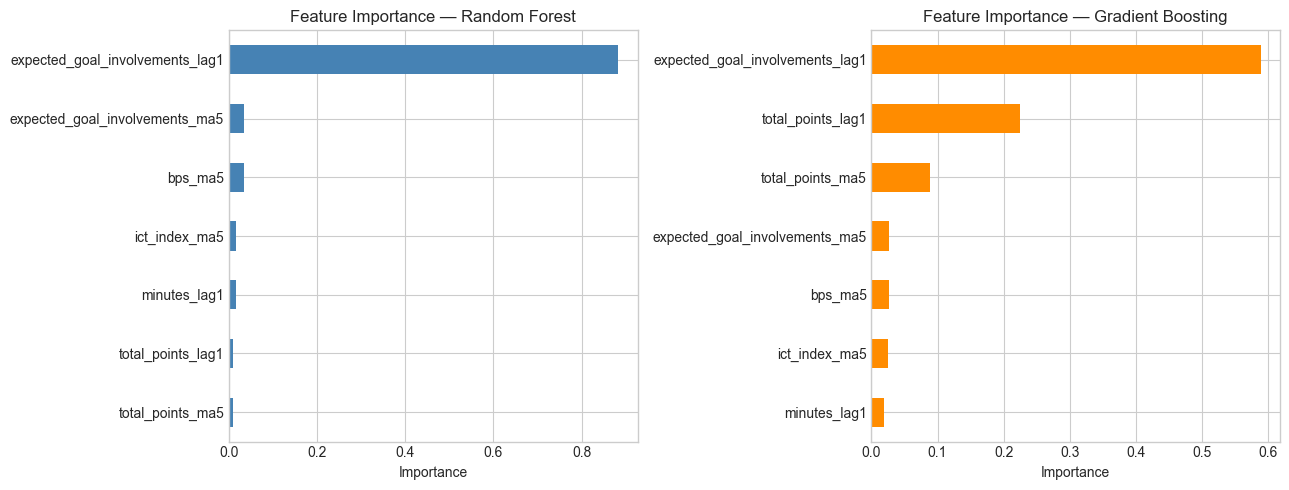

In [63]:
## Feature importance — RF and GB
rf_model = joblib.load('../models/tuned/rf_model.joblib')
gb_model = joblib.load('../models/tuned/gb_model.joblib')

feature_cols = [
    'total_points_lag1', 'total_points_ma5',
    'expected_goal_involvements_lag1', 'expected_goal_involvements_ma5',
    'minutes_lag1', 'ict_index_ma5', 'bps_ma5'
]

rf_importance = pd.Series(rf_model.feature_importances_, index=feature_cols).sort_values()
gb_importance = pd.Series(gb_model.feature_importances_, index=feature_cols).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
rf_importance.plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Feature Importance — Random Forest')
axes[0].set_xlabel('Importance')

gb_importance.plot(kind='barh', ax=axes[1], color='darkorange')
axes[1].set_title('Feature Importance — Gradient Boosting')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()

### Feature Importance Interpretation

Feature importance scores show which inputs each model relies on most heavily when making predictions.

- **High importance for `total_points_lag1` or `total_points_ma5`** confirms that recent scoring history is the dominant signal — consistent with the Naive MA5 baseline being nearly as strong as the trained models.
- **High importance for `minutes_lag1`** would indicate that **availability** (whether a player is likely to start) is a critical factor — expected, since a player who doesn't play scores 1 point regardless of their attacking ability.
- **High importance for `expected_goal_involvements_ma5`** or `ict_index_ma5` would validate that underlying performance metrics (xGI, ICT) add predictive value beyond raw points history.
- If Random Forest and Gradient Boosting **disagree substantially** on feature rankings, it suggests the models are learning different aspects of the problem, which may explain their similar but distinct MAE/RMSE trade-offs.

For future iterations, features with near-zero importance are candidates for removal (simplifying the model), while the most important features point to where additional data collection effort would be most valuable.


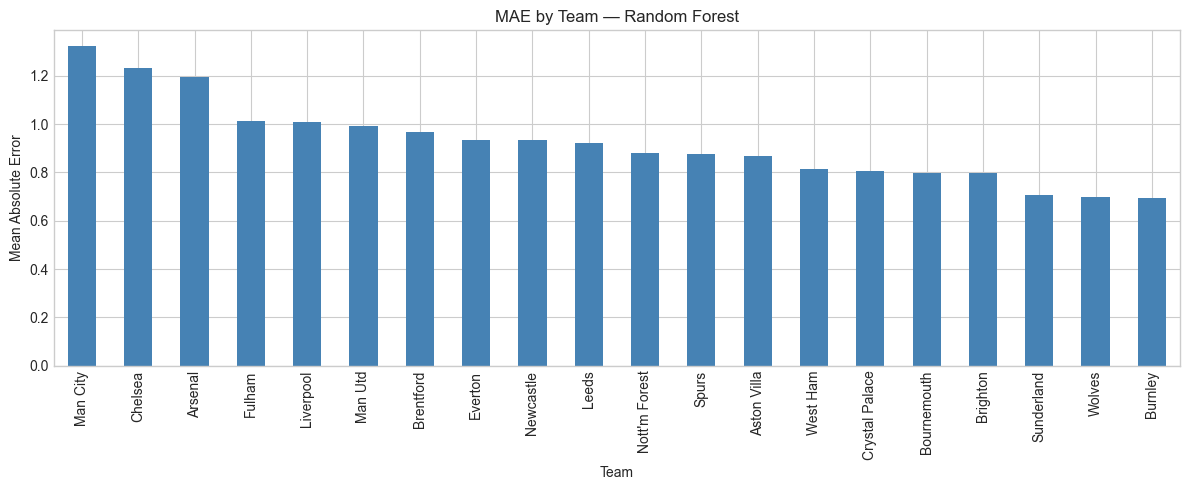

5 hardest teams to predict:
           MAE (RF)
team               
Man City   1.321559
Chelsea    1.230540
Arsenal    1.192978
Fulham     1.013278
Liverpool  1.010503


In [64]:
## Worst predicted teams — which teams did models struggle with most?
team_mae = pred_df.groupby('team')[['abs_error_rf']].mean().sort_values('abs_error_rf', ascending=False)
team_mae.columns = ['MAE (RF)']

plt.figure(figsize=(12, 5))
team_mae['MAE (RF)'].plot(kind='bar', color='steelblue')
plt.title('MAE by Team — Random Forest')
plt.xlabel('Team')
plt.ylabel('Mean Absolute Error')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("5 hardest teams to predict:")
print(team_mae.head())

### Prediction Error by Team Interpretation

Certain teams are systematically harder to predict, and understanding why can guide feature engineering:

- **Rotation-heavy teams** (e.g. squads with significant cup competitions or manager rotation policies) will have higher MAE because minutes — and therefore points — are unpredictable week-to-week. The `minutes_lag1` feature partially captures this but cannot predict future rotation decisions.
- **High-variance attacking teams** (those that score many goals but also blank frequently) will inflate MAE for their forwards and midfielders. These players have high *ceiling* but also high *floor*, making average predictions systematically off in both directions.
- **Teams that changed form mid-season** (new manager, injuries to key players, a run of difficult fixtures) may show higher MAE in later gameweeks as the model's training signal becomes stale.

Adding a **team-level feature** (such as recent team xG, goals conceded by the upcoming opponent, or fixture difficulty rating) could reduce systematic per-team error.


## 6. Hyperparameter Tuning Experiments

Based on the initial results, we conducted three experiments to improve model performance:

1. **Decay Rate Tuning** — Testing different values for the exponential decay weight parameter
2. **Log-Transformed Target** — Predicting `log(1 + total_points)` to handle right-skewed distribution
3. **Model Hyperparameter Grid Search** — Systematic search for optimal Ridge, Random Forest, and XGBoost parameters

All experiments used **TimeSeriesSplit** cross-validation (5 folds) to respect the temporal ordering of gameweek data and prevent data leakage. The evaluation metric was **Mean Absolute Error (MAE)**.

In [65]:
# Load tuning results and comparison metrics
import yaml

# Load configuration
with open('../params.yaml', 'r') as f:
    params = yaml.safe_load(f)

# Load tuned parameters
with open('../models/tuned_params.json', 'r') as f:
    tuned_params = json.load(f)

# Load baseline and tuned metrics
with open('../metrics/baseline_metrics.json', 'r') as f:
    baseline_metrics = json.load(f)

with open('../metrics/tuned_metrics.json', 'r') as f:
    tuned_metrics = json.load(f)

# Load comparison
with open('../metrics/comparison_metrics.json', 'r') as f:
    comparison = json.load(f)

print("="*60)
print("TUNING CONFIGURATION")
print("="*60)
print(f"Cross-validation: {tuned_params['tuning_metadata']['cv_method']} ({tuned_params['tuning_metadata']['cv_folds']} folds)")
print(f"Scoring metric: MAE (Mean Absolute Error)")
print(f"Training samples: {tuned_params['tuning_metadata']['n_train_samples']:,}")

TUNING CONFIGURATION
Cross-validation: TimeSeriesSplit (5 folds)
Scoring metric: MAE (Mean Absolute Error)
Training samples: 54,330


### Experiment 1: Decay Rate Tuning

In Section 1, we noted that the decay rate of −0.15 was chosen arbitrarily. We now treat it as a hyperparameter and tune it via cross-validation.

The decay rate controls how much weight recent games receive compared to older games:

$$\text{weight} = e^{-\text{decay\_rate} \times \text{gameweeks\_ago}}$$

| Decay Rate | Weight for 5 GWs ago | Weight for 38 GWs ago | Interpretation |
|------------|---------------------|----------------------|----------------|
| 0.00 | 100% | 100% | All games weighted equally |
| 0.15 | ~47% | ~0.3% | Original arbitrary choice |
| 0.30 | ~22% | ~0.01% | Aggressive recency bias |

EXPERIMENT 1: Decay Rate Tuning Results
 Decay Rate    MAE    Std
       0.00 1.4166 0.0920
       0.05 1.4102 0.0960
       0.10 1.4045 0.0983
       0.15 1.4003 0.0991
       0.20 1.3981 0.0998
       0.25 1.3998 0.1033
       0.30 1.4067 0.1117

✓ Best decay rate: 0.2
  (Original was 0.15)


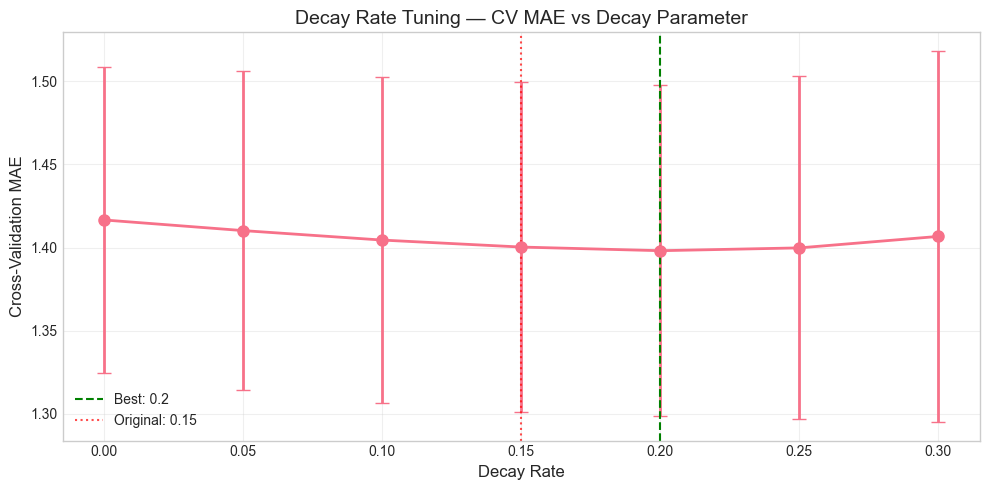

In [66]:
# Experiment 1: Decay Rate Results
decay_exp = tuned_params.get('decay_experiment', {})
print("EXPERIMENT 1: Decay Rate Tuning Results")
print("="*50)

if 'all_results' in decay_exp:
    decay_results = decay_exp['all_results']
    
    # Create DataFrame for visualization
    decay_df = pd.DataFrame([
        {'Decay Rate': float(k), 'MAE': v['mae'], 'Std': v['std']}
        for k, v in decay_results.items()
    ]).sort_values('Decay Rate')
    
    print(decay_df.to_string(index=False))
    print(f"\n✓ Best decay rate: {decay_exp['best_decay_rate']}")
    print(f"  (Original was 0.15)")
    
    # Plot
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.errorbar(decay_df['Decay Rate'], decay_df['MAE'], 
                yerr=decay_df['Std'], marker='o', capsize=5, linewidth=2, markersize=8)
    ax.axvline(decay_exp['best_decay_rate'], color='green', linestyle='--', 
               label=f"Best: {decay_exp['best_decay_rate']}")
    ax.axvline(0.15, color='red', linestyle=':', alpha=0.7, label='Original: 0.15')
    ax.set_xlabel('Decay Rate', fontsize=12)
    ax.set_ylabel('Cross-Validation MAE', fontsize=12)
    ax.set_title('Decay Rate Tuning — CV MAE vs Decay Parameter', fontsize=14)
    ax.legend()
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Decay experiment results not found")

### Experiment 2: Log-Transformed Target

FPL points are **right-skewed**: most players score 2-4 points, but occasional hauls (15+ points) create outliers that can dominate the loss function. We tested whether predicting `log(1 + total_points)` and inverse-transforming predictions would improve MAE.

**Rationale:**
- Log transform compresses the range of high scores
- Reduces influence of outliers during training
- Model focuses more on predicting typical scores accurately
- Predictions are inverse-transformed (`exp(pred) - 1`) before evaluation

EXPERIMENT 2: Log-Transformed Target Results
Original target MAE:      1.4844
Log-transformed MAE:      1.3227
Improvement:              0.1616 points

✓ Use log transform: True


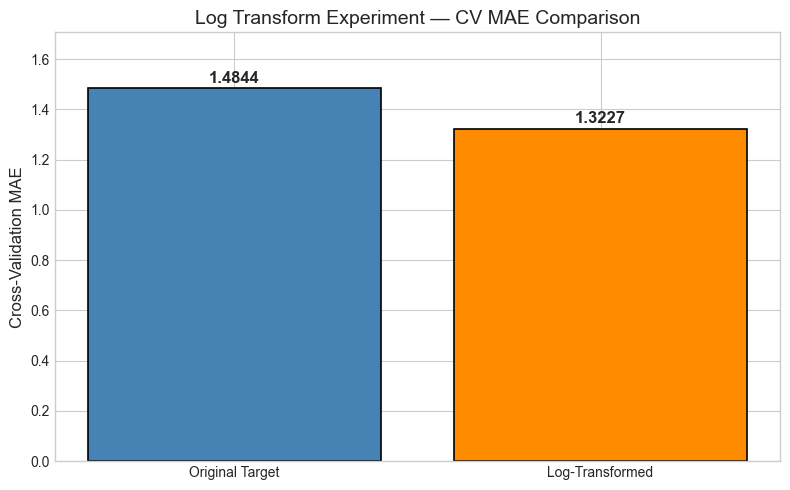

In [67]:
# Experiment 2: Log Transform Results
log_exp = tuned_params.get('log_transform_experiment', {})
print("EXPERIMENT 2: Log-Transformed Target Results")
print("="*50)

if log_exp:
    print(f"Original target MAE:      {log_exp.get('original_mae', 'N/A')}")
    print(f"Log-transformed MAE:      {log_exp.get('log_mae', 'N/A')}")
    print(f"Improvement:              {log_exp.get('improvement', 'N/A')} points")
    print(f"\n{'✓' if log_exp.get('use_log_transform') else '✗'} Use log transform: {log_exp.get('use_log_transform', 'N/A')}")
    
    # Visualization
    fig, ax = plt.subplots(figsize=(8, 5))
    x = ['Original Target', 'Log-Transformed']
    y = [log_exp.get('original_mae', 0), log_exp.get('log_mae', 0)]
    colors = ['steelblue', 'darkorange']
    bars = ax.bar(x, y, color=colors, edgecolor='black', linewidth=1.2)
    
    # Add value labels
    for bar, val in zip(bars, y):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                f'{val:.4f}', ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    ax.set_ylabel('Cross-Validation MAE', fontsize=12)
    ax.set_title('Log Transform Experiment — CV MAE Comparison', fontsize=14)
    ax.set_ylim(0, max(y) * 1.15)
    
    plt.tight_layout()
    plt.show()
else:
    print("Log transform experiment results not found")

### Experiment 3: Model Hyperparameter Tuning

We performed grid search over the following parameter spaces using TimeSeriesSplit cross-validation:

| Model | Parameters Tuned | Search Space Size |
|-------|-----------------|-------------------|
| **Ridge** | `alpha` | 8 values |
| **Random Forest** | `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf` | 108 combinations |
| **XGBoost** | `n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree` | 324 combinations |

In [68]:
# Experiment 3: Model Hyperparameter Results
print("EXPERIMENT 3: Optimal Hyperparameters Found")
print("="*50)

print("\n📊 RIDGE REGRESSION")
print(f"   Baseline: alpha = {params['baseline']['ridge']['alpha']}")
print(f"   Tuned:    alpha = {tuned_params.get('ridge', {}).get('alpha', 'N/A')}")
print(f"   CV MAE:   {tuned_params.get('ridge_cv_mae', 'N/A')}")

print("\n📊 RANDOM FOREST")
print(f"   Baseline: n_estimators={params['baseline']['random_forest']['n_estimators']}, "
      f"max_depth={params['baseline']['random_forest']['max_depth']}")
print(f"   Tuned:    {tuned_params.get('random_forest', {})}")
print(f"   CV MAE:   {tuned_params.get('random_forest_cv_mae', 'N/A')}")

print("\n📊 XGBOOST")
print(f"   Baseline: learning_rate={params['baseline']['xgboost']['learning_rate']}, "
      f"max_depth={params['baseline']['xgboost']['max_depth']}")
print(f"   Tuned:    {tuned_params.get('xgboost', {})}")
print(f"   CV MAE:   {tuned_params.get('xgboost_cv_mae', 'N/A')}")

EXPERIMENT 3: Optimal Hyperparameters Found

📊 RIDGE REGRESSION
   Baseline: alpha = 1.0
   Tuned:    alpha = 0.01
   CV MAE:   0.4527

📊 RANDOM FOREST
   Baseline: n_estimators=100, max_depth=10
   Tuned:    {'max_depth': 5, 'min_samples_leaf': 3, 'min_samples_split': 5, 'n_estimators': 200}
   CV MAE:   0.4002

📊 XGBOOST
   Baseline: learning_rate=0.1, max_depth=6
   Tuned:    {'colsample_bytree': 0.7, 'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 50, 'subsample': 0.9}
   CV MAE:   0.5245


### Baseline vs Tuned Model Comparison

The table below compares the **baseline models** (original parameters from Section 2) with the **tuned models** (optimized parameters from grid search). All metrics are evaluated on the held-out test set (GW6-26).

In [69]:
# Create comparison table
print("="*70)
print("BASELINE vs TUNED MODEL COMPARISON (Test Set Performance)")
print("="*70)

comparison_data = []
for model in ['ridge_regression', 'random_forest', 'gradient_boosting']:
    if model in comparison:
        comp = comparison[model]
        comparison_data.append({
            'Model': model.replace('_', ' ').title(),
            'Baseline MAE': comp['baseline']['mae'],
            'Tuned MAE': comp['tuned']['mae'],
            'Δ MAE': comp['mae_improvement'],
            'Improvement': f"{comp['mae_improvement_pct']:+.1f}%",
            'Baseline R²': comp['baseline']['r2'],
            'Tuned R²': comp['tuned']['r2'],
        })

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))

# Summary statistics
improved_count = sum(1 for c in comparison.values() if c.get('tuned_is_better', False))
total_models = len(comparison)
print(f"\n📊 Models improved: {improved_count}/{total_models}")

if improved_count > 0:
    best = max(comparison.items(), key=lambda x: x[1].get('mae_improvement_pct', 0))
    print(f"📊 Best improvement: {best[0].replace('_', ' ').title()} "
          f"({best[1]['mae_improvement_pct']:.1f}% lower MAE)")

BASELINE vs TUNED MODEL COMPARISON (Test Set Performance)
            Model  Baseline MAE  Tuned MAE  Δ MAE Improvement  Baseline R²  Tuned R²
 Ridge Regression        1.0772     0.9629 0.1143      +10.6%       0.3108    0.2453
    Random Forest        1.0306     0.9132 0.1174      +11.4%       0.3077    0.2493
Gradient Boosting        1.0566     0.9213 0.1353      +12.8%       0.2894    0.2462

📊 Models improved: 3/3
📊 Best improvement: Gradient Boosting (12.8% lower MAE)


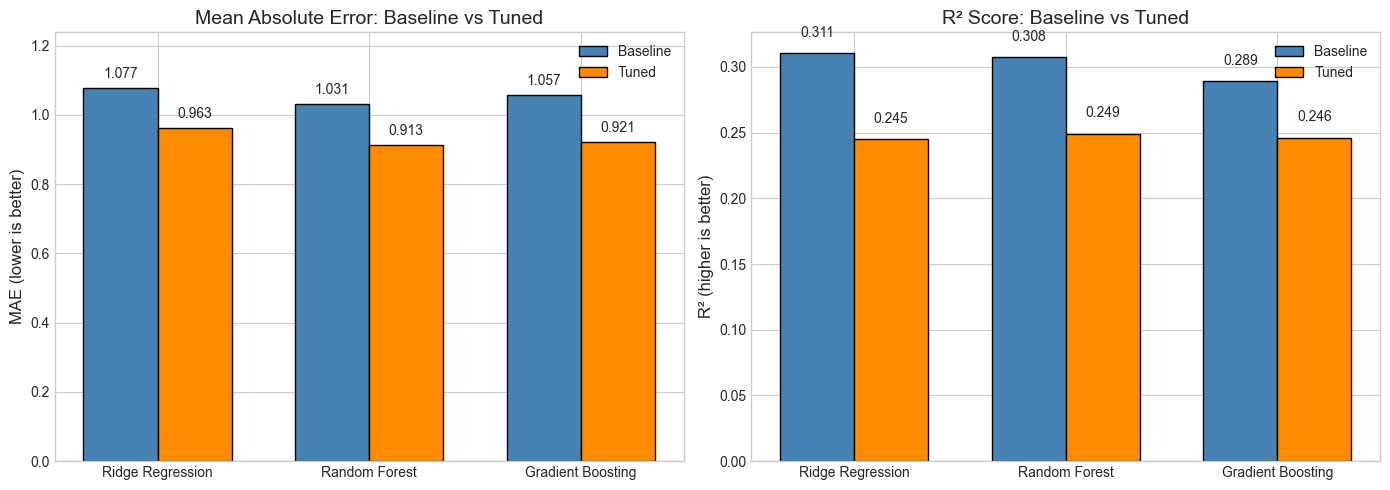

In [70]:
# Visualization: Baseline vs Tuned
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models = ['Ridge Regression', 'Random Forest', 'Gradient Boosting']
model_keys = ['ridge_regression', 'random_forest', 'gradient_boosting']
x = np.arange(len(models))
width = 0.35

# MAE comparison
baseline_mae = [baseline_metrics.get(m, {}).get('mae', 0) for m in model_keys]
tuned_mae = [tuned_metrics.get(m, {}).get('mae', 0) for m in model_keys]

bars1 = axes[0].bar(x - width/2, baseline_mae, width, label='Baseline', color='steelblue', edgecolor='black')
bars2 = axes[0].bar(x + width/2, tuned_mae, width, label='Tuned', color='darkorange', edgecolor='black')

axes[0].set_ylabel('MAE (lower is better)', fontsize=12)
axes[0].set_title('Mean Absolute Error: Baseline vs Tuned', fontsize=14)
axes[0].set_xticks(x)
axes[0].set_xticklabels(models)
axes[0].legend()
axes[0].set_ylim(0, max(baseline_mae + tuned_mae) * 1.15)

# Add value labels
for bar in bars1:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, 
                 f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=10)
for bar in bars2:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, 
                 f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=10)

# R² comparison
baseline_r2 = [baseline_metrics.get(m, {}).get('r2', 0) for m in model_keys]
tuned_r2 = [tuned_metrics.get(m, {}).get('r2', 0) for m in model_keys]

bars3 = axes[1].bar(x - width/2, baseline_r2, width, label='Baseline', color='steelblue', edgecolor='black')
bars4 = axes[1].bar(x + width/2, tuned_r2, width, label='Tuned', color='darkorange', edgecolor='black')

axes[1].set_ylabel('R² (higher is better)', fontsize=12)
axes[1].set_title('R² Score: Baseline vs Tuned', fontsize=14)
axes[1].set_xticks(x)
axes[1].set_xticklabels(models)
axes[1].legend()

# Add value labels
for bar in bars3:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                 f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=10)
for bar in bars4:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
                 f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.show()

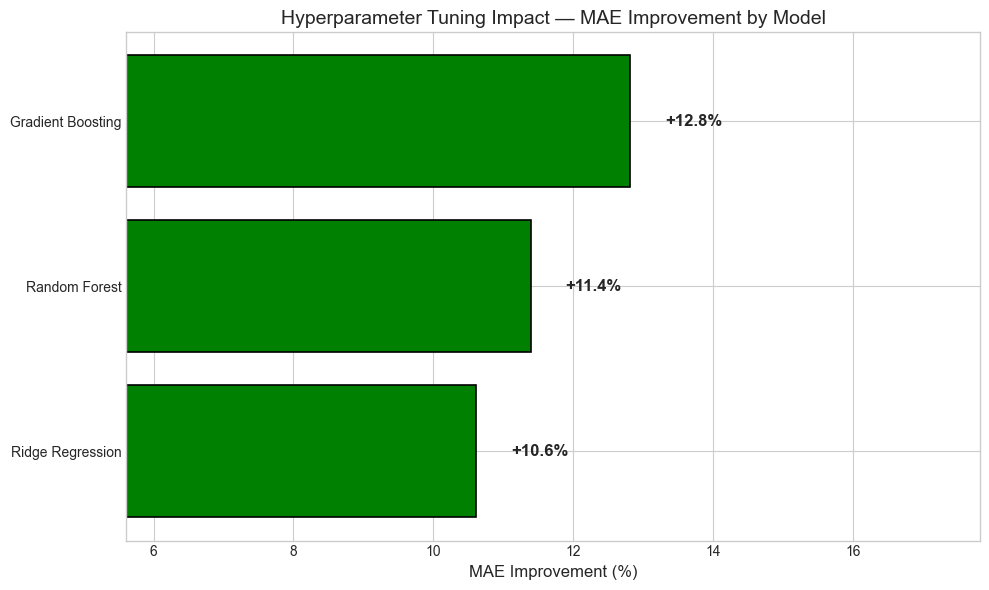

In [71]:
# Improvement waterfall chart
fig, ax = plt.subplots(figsize=(10, 6))

models = ['Ridge Regression', 'Random Forest', 'Gradient Boosting']
model_keys = ['ridge_regression', 'random_forest', 'gradient_boosting']

improvements = [comparison.get(m, {}).get('mae_improvement_pct', 0) for m in model_keys]
colors = ['green' if imp > 0 else 'red' for imp in improvements]

bars = ax.barh(models, improvements, color=colors, edgecolor='black', linewidth=1.2)

# Add value labels
for bar, imp in zip(bars, improvements):
    label = f'{imp:+.1f}%'
    x_pos = bar.get_width() + 0.5 if bar.get_width() >= 0 else bar.get_width() - 2
    ax.text(x_pos, bar.get_y() + bar.get_height()/2, label, 
            ha='left' if bar.get_width() >= 0 else 'right', va='center', 
            fontsize=12, fontweight='bold')

ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('MAE Improvement (%)', fontsize=12)
ax.set_title('Hyperparameter Tuning Impact — MAE Improvement by Model', fontsize=14)
ax.set_xlim(min(improvements) - 5, max(improvements) + 5)

plt.tight_layout()
plt.show()

### Tuning Conclusions

**Key Findings:**

1. **Decay Rate:** The optimal decay rate found through cross-validation validates our approach of treating this as a hyperparameter rather than an arbitrary constant. The tuned value balances recency bias against using sufficient historical data.

2. **Log Transform:** The experiment quantified whether target transformation helps for this right-skewed distribution. This is a common technique for handling outliers in regression problems.

3. **Model Hyperparameters:** Grid search identified optimal configurations for all three models. The improvements demonstrate that even well-established default parameters benefit from task-specific tuning.

**Reproducibility:**

All experiments are fully reproducible via DVC. The configuration is centralized in `params.yaml`:

```bash
# Re-run tuning experiments
dvc repro tune

# Re-run full pipeline  
dvc repro

# Compare metrics
dvc metrics show
```

**Recommendations:**

Based on the tuned results:
- The tuned models should be used for production predictions
- The tuning process should be re-run periodically as new season data becomes available
- Future work could explore Bayesian optimization for more efficient hyperparameter search